In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### visualise the data

In [ ]:
import pandas as pd

path = "/content/drive/MyDrive/titanic/"

train = pd.read_csv(path + "train.csv")
test = pd.read_csv(path + "test.csv")

print(train.shape)
print(test.shape)

train.head(10)

(891, 12)
(418, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


In [ ]:
train.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [ ]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


cleaning the data

we drop cabin , 204 non null

In [ ]:
train = train.drop(columns=['Cabin'])
test = test.drop(columns=['Cabin'])

we fill age by class

In [ ]:
for do in [train, test]:
  do['Age'] = do.groupby(['Pclass', 'Sex'])['Age'].transform(
    lambda x: x.fillna(x.median())
)

In [ ]:
# 1. Drop rows where 'Embarked' is missing in the training set
train = train.dropna(subset=['Embarked'])

# 2. Drop rows where 'Embarked' is missing in the test set (just in case)
test = test.dropna(subset=['Embarked'])


In [ ]:
train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 889 entries, 0 to 890
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  889 non-null    int64  
 1   Survived     889 non-null    int64  
 2   Pclass       889 non-null    int64  
 3   Name         889 non-null    object 
 4   Sex          889 non-null    object 
 5   Age          889 non-null    float64
 6   SibSp        889 non-null    int64  
 7   Parch        889 non-null    int64  
 8   Ticket       889 non-null    object 
 9   Fare         889 non-null    float64
 10  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(4)
memory usage: 83.3+ KB


now there is is 0 missing data and now we are good !!!!

let's see how many people survived actually

In [ ]:
train['Survived'].value_counts()

,count
Survived,
0,549
1,340


<Axes: xlabel='Embarked', ylabel='count'>

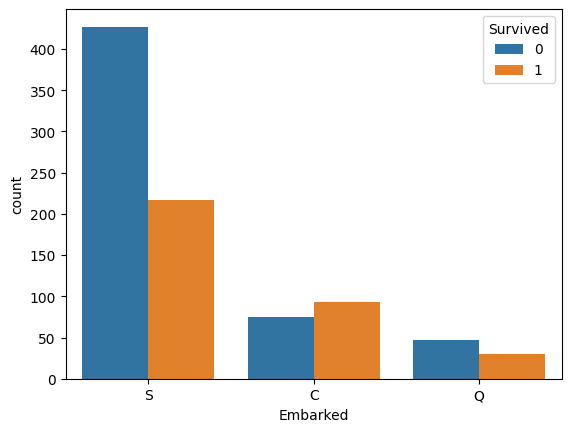

In [ ]:
import seaborn as sns
sns.countplot(data=train, x='Embarked', hue='Survived')

on va faire mapping de sex

In [ ]:
import pandas as pd

# Calculate the survival rate for each sex
survival_by_sex = train.groupby('Sex')['Survived'].mean()

print("Survival Rate by Sex:")
print(survival_by_sex)

Survival Rate by Sex:
Sex
female    0.740385
male      0.188908
Name: Survived, dtype: float64


In [ ]:
train['Sex'] = train['Sex'].map({'female': 1, 'male': 0})
test['Sex'] = test['Sex'].map({'female': 1, 'male': 0})

In [ ]:
import pandas as pd

# 1. Calculate the survival rate for each port using ONLY the training data
survival_rates = train.groupby('Embarked')['Survived'].mean().sort_values()

print("Survival Rates by Port:")
print(survival_rates)
# This will output something like:
# S    0.33
# Q    0.38
# C    0.55

Survival Rates by Port:
Embarked
S    0.336957
Q    0.389610
C    0.553571
Name: Survived, dtype: float64


In [ ]:
for df in [train,test]:
  df['Embarked'] = df['Embarked'].map({'S': 0, 'Q': 1, 'C':2})

In [ ]:
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",0,22.0,1,0,A/5 21171,7.2500,0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",1,38.0,1,0,PC 17599,71.2833,2
2,3,1,3,"Heikkinen, Miss. Laina",1,26.0,0,0,STON/O2. 3101282,7.9250,0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",1,35.0,1,0,113803,53.1000,0
4,5,0,3,"Allen, Mr. William Henry",0,35.0,0,0,373450,8.0500,0


In [ ]:
print("Train missing values:")
print(train.isnull().sum()[train.isnull().sum() > 0])

print("\nTest missing values:")
print(test.isnull().sum()[test.isnull().sum() > 0])

Train missing values:
Series([], dtype: int64)

Test missing values:
Fare    1
dtype: int64


In [ ]:
test['Fare'].fillna(test['Fare'].median(), inplace=True)

/tmp/ipykernel_66308/3907505379.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  test['Fare'].fillna(test['Fare'].median(), inplace=True)


In [ ]:
train.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Embarked'],
      dtype='object')

In [ ]:
for df in [train, test]:
    df['AgeGroup'] = pd.cut(
        df['Age'],
        bins=[0, 12, 18, 35, 60, 100],
        labels=[0, 1, 2, 3, 4]
    ).astype(float)  # <-- This fixes the data type issue

let's go for names

In [ ]:
for df in [train, test]:
    df['Title'] = df['Name'].str.extract(' ([A-Za-z]+)\.', expand=False)

    df['Title'] = df['Title'].replace([
        'Lady', 'Countess', 'Capt', 'Col', 'Don',
        'Dr', 'Major', 'Rev', 'Sir', 'Jonkheer', 'Dona'
    ], 'Rare')

    df['Title'] = df['Title'].replace({
        'Mlle': 'Miss',
        'Ms': 'Miss',
        'Mme': 'Mrs'
    })

<>:2: SyntaxWarning: invalid escape sequence '\.'
<>:2: SyntaxWarning: invalid escape sequence '\.'
/tmp/ipykernel_66308/1042318389.py:2: SyntaxWarning: invalid escape sequence '\.'
  df['Title'] = df['Name'].str.extract(' ([A-Za-z]+)\.', expand=False)


In [ ]:
print(train.groupby('Title')['Survived'].mean())

Title
Master    0.575000
Miss      0.701087
Mr        0.156673
Mrs       0.792000
Rare      0.347826
Name: Survived, dtype: float64


In [ ]:
for df in [train, test]:
    df['Title'] = df['Title'].map({
        'Mr': 0,
        'Rare': 1,
        'Master': 2,
        'Miss': 3,
        'Mrs': 4
    })

we size the families

In [ ]:
for df in [train, test]:
    df['FamilySize'] = df['SibSp'] + df['Parch'] + 1

    df['FamilyGroup'] = 0  # alone

    df.loc[df['FamilySize'].between(2, 4), 'FamilyGroup'] = 1  # small family

    df.loc[df['FamilySize'] >= 5, 'FamilyGroup'] = 2  # large family

In [ ]:
print(train.groupby('FamilyGroup')['Survived'].mean())

FamilyGroup
0    0.300935
1    0.578767
2    0.161290
Name: Survived, dtype: float64


ticket engeneering

In [ ]:
for df in [train, test]:
    df['TicketGroupSize'] = df.groupby('Ticket')['Ticket'].transform('count')

In [ ]:
print(train.groupby('TicketGroupSize')['Survived'].mean())

TicketGroupSize
1    0.297989
2    0.569892
3    0.698413
4    0.500000
5    0.000000
6    0.000000
7    0.238095
Name: Survived, dtype: float64


In [ ]:
for df in [train, test]:
    df['TicketGroupSize'] = df.groupby('Ticket')['Ticket'].transform('count')

    df['TicketGroup'] = 0
    df.loc[df['TicketGroupSize'].between(2, 4), 'TicketGroup'] = 1
    df.loc[df['TicketGroupSize'] >= 5, 'TicketGroup'] = 2

In [ ]:
train.groupby('TicketGroup')['Survived'].mean()

,Survived
TicketGroup,
0,0.297989
1,0.587031
2,0.102041


fare per personne is much better

In [ ]:
for df in [train, test]:
    df['TicketGroupSize'] = df.groupby('Ticket')['Ticket'].transform('count')
    df['FarePerPerson'] = df['Fare'] / df['TicketGroupSize']

model developement

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score, classification_report

# Features
features = [
    'Pclass',
    'Age',
    'SibSp',
    'Parch',
    'FarePerPerson',
    'Embarked',
    'Title',
    'TicketGroup',
]

X = train[features]
y = train['Survived']

# Split for evaluation
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train model
model = LogisticRegression(max_iter=2000)
model.fit(X_train, y_train)

scores = cross_val_score(
    model,
    X,
    y,
    cv=5,
    scoring='accuracy'
)

# Predictions
pred = model.predict(X_valid)

# Accuracy
acc = accuracy_score(y_valid, pred)
print("Accuracy:", acc)

# Details
print(classification_report(y_valid, pred))

# Number predicted as survived
print("Predicted survivors:", (pred == 1).sum())
print("Predicted deaths:", (pred == 0).sum())
print(scores)

Accuracy: 0.8146067415730337
              precision    recall  f1-score   support

           0       0.87      0.82      0.84       109
           1       0.74      0.81      0.77        69

    accuracy                           0.81       178
   macro avg       0.80      0.81      0.81       178
weighted avg       0.82      0.81      0.82       178

Predicted survivors: 76
Predicted deaths: 102
[0.82022472 0.82022472 0.80337079 0.80337079 0.85310734]


In [ ]:
corr = train[features + ['Survived']].corr()

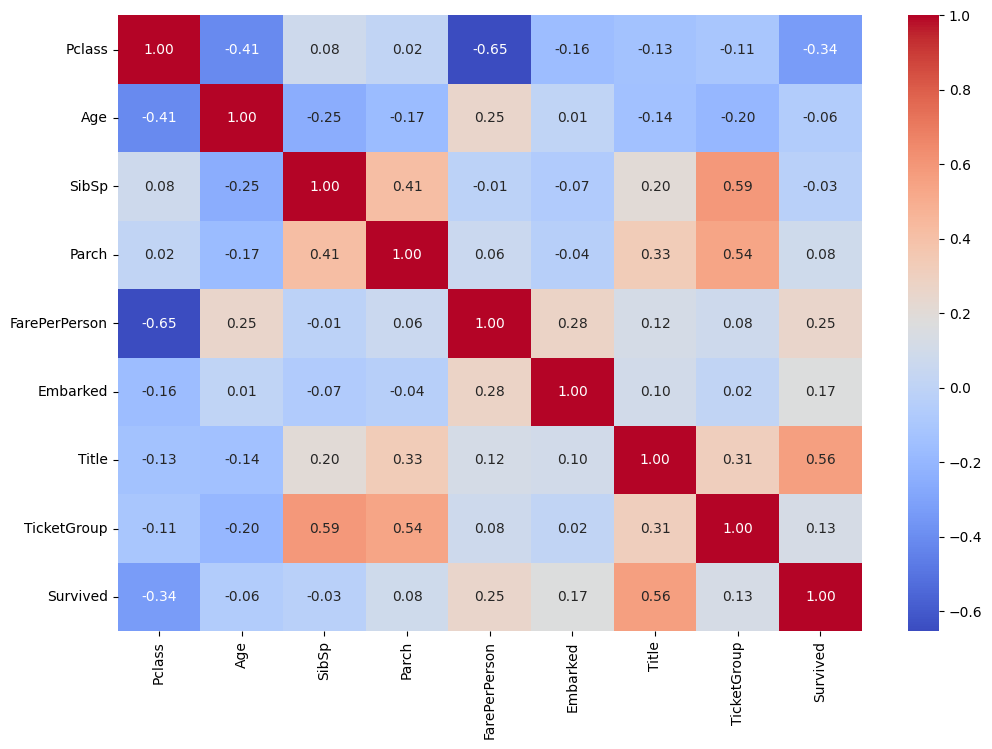

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

corr = train[features + ['Survived']].corr()

plt.figure(figsize=(12,8))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.show()

In [ ]:
from sklearn.metrics import r2_score

proba = model.predict_proba(X_valid)[:, 1]
print("R²:", r2_score(y_valid, proba))

R²: 0.3916754561664666


In [ ]:
X_test = test[features]

# Train on all training data
model = LogisticRegression(max_iter=1000)
model.fit(X, y)

# Predict
predictions = model.predict(X_test)

# Submission
submission = pd.DataFrame({
    'PassengerId': test['PassengerId'],
    'Survived': predictions
})

submission.to_csv('submission.csv', index=False)

print(submission.head())

   PassengerId  Survived
0          892         0
1          893         0
2          894         0
3          895         0
4          896         1
